# E-commerce Pandas Practice

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("ecommerce_dirty_sample.csv")
df.head()

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,total_amount,payment_method,order_status,city
0,ORD1001,2026-01-03,CUST001,Laptop,Electronics,1,899.99,899.99,Credit Card,Shipped,Chennai
1,ORD1002,2026-01-04,CUST002,wireless mouse,Electronics,2,19.99,39.98,UPI,Delivered,Bengaluru
2,ORD1003,2026-01-05,CUST003,Office Chair,Furniture,1,149.50,149.50,Cash on Delivery,Delivered,Mumbai
3,ORD1004,2026-01-06,CUST004,Smartphone,Electronics,1,699.00,699.00,NaN,Processing,Hyderabad
4,ORD1005,2026-01-07,CUST005,Coffee Maker,Home Appliances,2,45.00,90.00,UPI,Delivered,Pune


In [2]:
df.tail()

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,total_amount,payment_method,order_status,city
99,ORD1100,2026-04-12,CUST100,Water Bottle,Home & Kitchen,4,12.00,48.00,UPI,Delivered,Ahmedabad
100,ORD1002,2026-01-04,CUST002,wireless mouse,Electronics,2,19.99,39.98,UPI,Delivered,Bengaluru
101,ORD1009,not-a-date,CUST009,Desk Lamp,Home Decor,2,24.50,49.00,Debit Card,Delivered,Jaipur
102,ORD1016,2026-01-18,CUST016,laptop,Electronics,1,899.99,899.99,credit card,Shipped,Chennai
103,ORD1034,2026-02-05,CUST034,Monitor,Electronics,1,699.00,699.00,Credit Card,Processing,Hyderabad


In [3]:
df.shape

(104, 11)

In [4]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'product_name', 'category',
       'quantity', 'unit_price', 'total_amount', 'payment_method',
       'order_status', 'city'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        104 non-null    str    
 1   order_date      103 non-null    str    
 2   customer_id     101 non-null    str    
 3   product_name    103 non-null    str    
 4   category        103 non-null    str    
 5   quantity        104 non-null    str    
 6   unit_price      102 non-null    float64
 7   total_amount    102 non-null    float64
 8   payment_method  103 non-null    str    
 9   order_status    103 non-null    str    
 10  city            103 non-null    str    
dtypes: float64(2), str(9)
memory usage: 9.1 KB


In [6]:
df.describe(include='all')

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,total_amount,payment_method,order_status,city
count,104,103,101,103,103,104,102.000000,1.020000e+02,103,103,103
unique,100,99,97,20,10,10,NaN,NaN,6,6,14
top,ORD1002,2026-01-04,CUST002,Desk Lamp,Electronics,1,NaN,NaN,UPI,Delivered,Chennai
freq,2,2,2,8,41,52,NaN,NaN,36,56,26
mean,NaN,NaN,NaN,NaN,NaN,NaN,9976.214706,9.824241e+04,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,98997.900387,9.901273e+05,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,-45.000000,0.000000e+00,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,22.500000,4.800000e+01,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,59.990000,8.997000e+01,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,149.500000,1.495000e+02,NaN,NaN,NaN


In [7]:
df['order_id'].nunique()

100

In [8]:
df.isna().sum()

order_id          0
order_date        1
customer_id       3
product_name      1
category          1
quantity          0
unit_price        2
total_amount      2
payment_method    1
order_status      1
city              1
dtype: int64

In [9]:
df.isna().sum()

order_id          0
order_date        1
customer_id       3
product_name      1
category          1
quantity          0
unit_price        2
total_amount      2
payment_method    1
order_status      1
city              1
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(3)

In [11]:
df[df.duplicated(keep=False)]

,order_id,order_date,customer_id,product_name,category,quantity,unit_price,total_amount,payment_method,order_status,city
1,ORD1002,2026-01-04,CUST002,wireless mouse,Electronics,2,19.99,39.98,UPI,Delivered,Bengaluru
8,ORD1009,not-a-date,CUST009,Desk Lamp,Home Decor,2,24.50,49.00,Debit Card,Delivered,Jaipur
15,ORD1016,2026-01-18,CUST016,laptop,Electronics,1,899.99,899.99,credit card,Shipped,Chennai
100,ORD1002,2026-01-04,CUST002,wireless mouse,Electronics,2,19.99,39.98,UPI,Delivered,Bengaluru
101,ORD1009,not-a-date,CUST009,Desk Lamp,Home Decor,2,24.50,49.00,Debit Card,Delivered,Jaipur
102,ORD1016,2026-01-18,CUST016,laptop,Electronics,1,899.99,899.99,credit card,Shipped,Chennai


In [12]:
df = df.drop_duplicates().copy()

In [13]:
df = df.rename(columns={
    "order_id": "OrderID",
    "order_date": "Date",
    "customer_id": "CustomerID",
    "product_name": "Product",
    "category": "Category",
    "quantity": "Units",
    "unit_price": "UnitPrice",
    "total_amount": "ReportedAmount",
    "payment_method": "PaymentMethod",
    "order_status": "OrderStatus",
    "city": "Region"
})
df.head()

,OrderID,Date,CustomerID,Product,Category,Units,UnitPrice,ReportedAmount,PaymentMethod,OrderStatus,Region
0,ORD1001,2026-01-03,CUST001,Laptop,Electronics,1,899.99,899.99,Credit Card,Shipped,Chennai
1,ORD1002,2026-01-04,CUST002,wireless mouse,Electronics,2,19.99,39.98,UPI,Delivered,Bengaluru
2,ORD1003,2026-01-05,CUST003,Office Chair,Furniture,1,149.50,149.50,Cash on Delivery,Delivered,Mumbai
3,ORD1004,2026-01-06,CUST004,Smartphone,Electronics,1,699.00,699.00,NaN,Processing,Hyderabad
4,ORD1005,2026-01-07,CUST005,Coffee Maker,Home Appliances,2,45.00,90.00,UPI,Delivered,Pune


In [14]:
for col in ["OrderID", "CustomerID", "Product", "Category", "PaymentMethod", "OrderStatus", "Region"]:
    df[col] = df[col].astype("string").str.strip()

df["Product"] = df["Product"].str.title()
df["Category"] = df["Category"].str.title()
df["PaymentMethod"] = df["PaymentMethod"].str.title()
df["OrderStatus"] = df["OrderStatus"].str.title()
df["Region"] = df["Region"].str.title()

df["Units"] = pd.to_numeric(df["Units"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
df["ReportedAmount"] = pd.to_numeric(df["ReportedAmount"], errors="coerce")
df[["Units", "UnitPrice", "ReportedAmount"]].isna().sum()

Units             2
UnitPrice         2
ReportedAmount    2
dtype: int64

In [15]:
df[(df['Units'].isna()) | (df['Units'] <= 0) | (df['Units'] > 100)]

,OrderID,Date,CustomerID,Product,Category,Units,UnitPrice,ReportedAmount,PaymentMethod,OrderStatus,Region
16,ORD1017,2026-01-19,CUST017,Wireless Mouse,Electronics,NaN,19.99,39.98,Upi,Delivered,Bengaluru
39,ORD1040,2026-02-11,CUST040,Water Bottle,Home & Kitchen,-2.0,12.00,48.00,Upi,Delivered,Ahmedabad
60,ORD1061,2026-03-04,CUST061,Laptop,Electronics,10000.0,899.99,899.99,Credit Card,Shipped,Chennai
95,ORD1096,2026-04-08,CUST096,Running Shoes,Fashion,NaN,79.99,79.99,Debit Card,Shipped,Delhi


In [16]:
df[(df['UnitPrice'].isna()) | (df['UnitPrice'] <= 0) | (df['UnitPrice'] > 100000)]

,OrderID,Date,CustomerID,Product,Category,Units,UnitPrice,ReportedAmount,PaymentMethod,OrderStatus,Region
11,ORD1012,2026-01-14,CUST012,Notebook Set,Stationery,5.0,NaN,24.95,Cash On Delivery,Delivered,Lucknow
18,ORD1019,2026-01-21,CUST019,Smartphone,Electronics,1.0,NaN,699.00,Upi,Processing,Hyderabad
35,ORD1036,2026-02-07,CUST036,Running Shoes,Fashion,1.0,999999.99,79.99,Debit Card,Shipped,Delhi
64,ORD1065,2026-03-08,CUST065,Coffee Maker,Home Appliances,2.0,-45.00,90.00,Upi,Delivered,Pune


In [17]:
df[df['ReportedAmount'] < 0]

,OrderID,Date,CustomerID,Product,Category,Units,UnitPrice,ReportedAmount,PaymentMethod,OrderStatus,Region


In [18]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce", format="mixed")
df["Date"].isna().sum()

np.int64(3)

In [19]:
df[df['Date'].isna()]

,OrderID,Date,CustomerID,Product,Category,Units,UnitPrice,ReportedAmount,PaymentMethod,OrderStatus,Region
8,ORD1009,NaT,CUST009,Desk Lamp,Home Decor,2.0,24.50,49.00,Debit Card,Delivered,Jaipur
45,ORD1046,NaT,CUST046,Laptop,Electronics,1.0,899.99,899.99,Credit Card,Shipped,Chennai
90,ORD1091,NaT,CUST091,Laptop,Electronics,1.0,899.99,899.99,Credit Card,Shipped,Chennai


In [20]:
df["Year"] = df["Date"].dt.year
df["MonthNumber"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["Month"] = df["Date"].dt.strftime("%Y-%m")
df = df.sort_values("Date", na_position="last").reset_index(drop=True)
df[["Date", "Year", "MonthNumber", "Day", "Month"]].head()

,Date,Year,MonthNumber,Day,Month
0,2026-01-03,2026.0,1.0,3.0,2026-01
1,2026-01-04,2026.0,1.0,4.0,2026-01
2,2026-01-05,2026.0,1.0,5.0,2026-01
3,2026-01-06,2026.0,1.0,6.0,2026-01
4,2026-01-07,2026.0,1.0,7.0,2026-01


In [21]:
df["DiscountPct"] = 0.0
valid_revenue_inputs = (
    df["Units"].notna()
    & df["UnitPrice"].notna()
    & (df["Units"] > 0)
    & (df["Units"] <= 100)
    & (df["UnitPrice"] > 0)
    & (df["UnitPrice"] <= 100000)
)
df["Revenue"] = np.where(
    valid_revenue_inputs,
    df["Units"] * df["UnitPrice"] * (1 - df["DiscountPct"]),
    np.nan
)
df[["OrderID", "Units", "UnitPrice", "DiscountPct", "Revenue"]].head()

,OrderID,Units,UnitPrice,DiscountPct,Revenue
0,ORD1001,1.0,899.99,0.0,899.99
1,ORD1002,2.0,19.99,0.0,39.98
2,ORD1003,1.0,149.50,0.0,149.50
3,ORD1004,1.0,699.00,0.0,699.00
4,ORD1005,2.0,45.00,0.0,90.00


In [22]:
df['Revenue'].isna().sum()

np.int64(8)

In [23]:
df.sort_values('Revenue', ascending=False).head(5)

,OrderID,Date,CustomerID,Product,Category,Units,UnitPrice,ReportedAmount,PaymentMethod,OrderStatus,Region,Year,MonthNumber,Day,Month,DiscountPct,Revenue
0,ORD1001,2026-01-03,CUST001,Laptop,Electronics,1.0,899.99,899.99,Credit Card,Shipped,Chennai,2026.0,1.0,3.0,2026-01,0.0,899.99
13,ORD1016,2026-01-18,CUST016,Laptop,Electronics,1.0,899.99,899.99,Credit Card,Shipped,Chennai,2026.0,1.0,18.0,2026-01,0.0,899.99
28,ORD1031,2026-02-02,<NA>,Laptop,Electronics,1.0,899.99,899.99,Credit Card,Shipped,Chennai,2026.0,2.0,2.0,2026-02,0.0,899.99
99,ORD1046,NaT,CUST046,Laptop,Electronics,1.0,899.99,899.99,Credit Card,Shipped,Chennai,NaN,NaN,NaN,NaN,0.0,899.99
100,ORD1091,NaT,CUST091,Laptop,Electronics,1.0,899.99,899.99,Credit Card,Shipped,Chennai,NaN,NaN,NaN,NaN,0.0,899.99


In [24]:
df[['OrderID', 'Date', 'Region', 'Product', 'Units', 'UnitPrice', 'DiscountPct', 'Revenue']].head()

,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Revenue
0,ORD1001,2026-01-03,Chennai,Laptop,1.0,899.99,0.0,899.99
1,ORD1002,2026-01-04,Bengaluru,Wireless Mouse,2.0,19.99,0.0,39.98
2,ORD1003,2026-01-05,Mumbai,Office Chair,1.0,149.50,0.0,149.50
3,ORD1004,2026-01-06,Hyderabad,Smartphone,1.0,699.00,0.0,699.00
4,ORD1005,2026-01-07,Pune,Coffee Maker,2.0,45.00,0.0,90.00


In [25]:
df.loc[df['Revenue'] > 500, ['OrderID', 'Product', 'Revenue']]

,OrderID,Product,Revenue
0,ORD1001,Laptop,899.99
3,ORD1004,Smartphone,699.00
13,ORD1016,Laptop,899.99
28,ORD1031,Laptop,899.99
31,ORD1034,Smartphone,699.00
32,ORD1034,Monitor,699.00
46,ORD1049,Smartphone,699.00
61,ORD1064,Smartphone,699.00
73,ORD1076,Wireless Mouse,899.99
76,ORD1079,Smartphone,699.00


In [26]:
df.loc[df['DiscountPct'] > 0.10, ['OrderID', 'Product', 'DiscountPct']]

,OrderID,Product,DiscountPct


In [27]:
df.loc[df['Units'] > 2, ['OrderID', 'Product', 'Units']]

,OrderID,Product,Units
5,ORD1007,Backpack,3.0
7,ORD1010,Water Bottle,4.0
9,ORD1012,Notebook Set,5.0
19,ORD1022,Backpack,3.0
22,ORD1025,Water Bottle,4.0
24,ORD1027,Notebook Set,5.0
25,ORD1028,Gaming Keyboard,3.5
29,ORD1032,Wireless Mouse,3.0
35,ORD1037,Backpack,3.0
40,ORD1042,Notebook Set,5.0


In [28]:
df.loc[(df['Region'] == 'Chennai') | (df['Product'] == 'Laptop'), ['OrderID', 'Region', 'Product', 'Revenue']]

,OrderID,Region,Product,Revenue
0,ORD1001,Chennai,Laptop,899.99
6,ORD1008,Chennai,Bluetooth Speaker,59.99
8,ORD1011,Chennai,Monitor,229.99
12,ORD1015,Chennai,Air Fryer,129.99
13,ORD1016,Chennai,Laptop,899.99
20,ORD1023,Chennai,Bluetooth Speaker,59.99
22,ORD1025,Chennai,Water Bottle,48.00
23,ORD1026,Chennai,Monitor,229.99
27,ORD1030,Chennai,Air Fryer,129.99
28,ORD1031,Chennai,Laptop,899.99


In [29]:
df.loc[(df['Revenue'] > 100) & (df['Units'] >= 1), ['OrderID', 'Product', 'Units', 'Revenue']]

,OrderID,Product,Units,Revenue
0,ORD1001,Laptop,1.0,899.990
2,ORD1003,Office Chair,1.0,149.500
3,ORD1004,Smartphone,1.0,699.000
8,ORD1011,Monitor,1.0,229.990
12,ORD1015,Air Fryer,1.0,129.990
13,ORD1016,Laptop,1.0,899.990
15,ORD1018,Office Chair,1.0,149.500
23,ORD1026,Monitor,1.0,229.990
25,ORD1028,Gaming Keyboard,3.5,314.965
27,ORD1030,Air Fryer,1.0,129.990


In [30]:
df.loc[:4, ['OrderID', 'Product', 'Revenue']]

,OrderID,Product,Revenue
0,ORD1001,Laptop,899.99
1,ORD1002,Wireless Mouse,39.98
2,ORD1003,Office Chair,149.50
3,ORD1004,Smartphone,699.00
4,ORD1005,Coffee Maker,90.00


In [31]:
df.iloc[:5, :4]

,OrderID,Date,CustomerID,Product
0,ORD1001,2026-01-03,CUST001,Laptop
1,ORD1002,2026-01-04,CUST002,Wireless Mouse
2,ORD1003,2026-01-05,CUST003,Office Chair
3,ORD1004,2026-01-06,CUST004,Smartphone
4,ORD1005,2026-01-07,CUST005,Coffee Maker


In [32]:
df.reset_index(drop=True).head()

,OrderID,Date,CustomerID,Product,Category,Units,UnitPrice,ReportedAmount,PaymentMethod,OrderStatus,Region,Year,MonthNumber,Day,Month,DiscountPct,Revenue
0,ORD1001,2026-01-03,CUST001,Laptop,Electronics,1.0,899.99,899.99,Credit Card,Shipped,Chennai,2026.0,1.0,3.0,2026-01,0.0,899.99
1,ORD1002,2026-01-04,CUST002,Wireless Mouse,Electronics,2.0,19.99,39.98,Upi,Delivered,Bengaluru,2026.0,1.0,4.0,2026-01,0.0,39.98
2,ORD1003,2026-01-05,CUST003,Office Chair,Furniture,1.0,149.50,149.50,Cash On Delivery,Delivered,Mumbai,2026.0,1.0,5.0,2026-01,0.0,149.50
3,ORD1004,2026-01-06,CUST004,Smartphone,Electronics,1.0,699.00,699.00,<NA>,Processing,Hyderabad,2026.0,1.0,6.0,2026-01,0.0,699.00
4,ORD1005,2026-01-07,CUST005,Coffee Maker,Home Appliances,2.0,45.00,90.00,Upi,Delivered,Pune,2026.0,1.0,7.0,2026-01,0.0,90.00


In [33]:
region_summary = df.groupby("Region").agg(
    TotalRevenue=("Revenue", "sum"),
    Orders=("OrderID", "nunique"),
    AverageRevenuePerOrder=("Revenue", "mean")
).sort_values("TotalRevenue", ascending=False)
region_summary

,TotalRevenue,Orders,AverageRevenuePerOrder
Region,,,
Chennai,7876.750,28,291.731481
Hyderabad,4893.000,7,699.000000
Mumbai,1046.500,7,149.500000
Bengaluru,1024.785,13,85.398750
Pune,540.000,7,90.000000
Kolkata,539.820,6,89.970000
Delhi,399.950,7,79.990000
Jaipur,294.000,6,49.000000
Coimbatore,270.000,6,45.000000


In [34]:
product_summary = df.groupby("Product").agg(
    TotalRevenue=("Revenue", "sum"),
    UnitsSold=("Units", "sum"),
    Orders=("OrderID", "nunique")
).sort_values("TotalRevenue", ascending=False)
product_summary

,TotalRevenue,UnitsSold,Orders
Product,,,
Laptop,4499.950,10005.0,6
Smartphone,4194.000,7.0,7
Monitor,1878.940,7.0,7
Wireless Mouse,1159.860,14.0,8
Office Chair,897.000,6.0,6
Air Fryer,779.940,6.0,6
Gaming Keyboard,764.915,8.5,6
Backpack,629.790,21.0,7
Coffee Maker,540.000,14.0,7


In [35]:
product_summary.head(1)

,TotalRevenue,UnitsSold,Orders
Product,,,
Laptop,4499.95,10005.0,6


In [36]:
monthly_summary = df.dropna(subset=["Month"]).groupby("Month").agg(
    TotalRevenue=("Revenue", "sum"),
    Orders=("OrderID", "nunique")
).sort_index()
monthly_summary

,TotalRevenue,Orders
Month,,
2026-01,4652.745,27
2026-02,5006.700,27
2026-03,4350.680,31
2026-04,1400.430,11
2026-08,79.990,1


In [37]:
monthly_summary['TotalRevenue'].idxmax()

'2026-02'

In [38]:
highest_revenue_orders = df.sort_values("Revenue", ascending=False)[
    ["OrderID", "Date", "Region", "Product", "Units", "UnitPrice", "DiscountPct", "Revenue"]
].head(5)
highest_revenue_orders

,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Revenue
0,ORD1001,2026-01-03,Chennai,Laptop,1.0,899.99,0.0,899.99
13,ORD1016,2026-01-18,Chennai,Laptop,1.0,899.99,0.0,899.99
28,ORD1031,2026-02-02,Chennai,Laptop,1.0,899.99,0.0,899.99
99,ORD1046,NaT,Chennai,Laptop,1.0,899.99,0.0,899.99
100,ORD1091,NaT,Chennai,Laptop,1.0,899.99,0.0,899.99


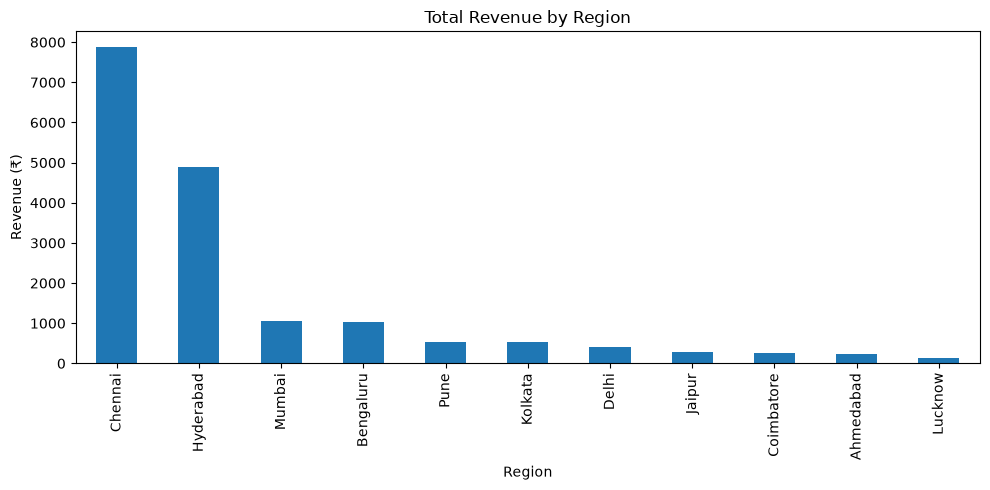

In [39]:
region_summary["TotalRevenue"].plot(kind="bar", figsize=(10, 5))
plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue (₹)")
plt.tight_layout()
plt.show()

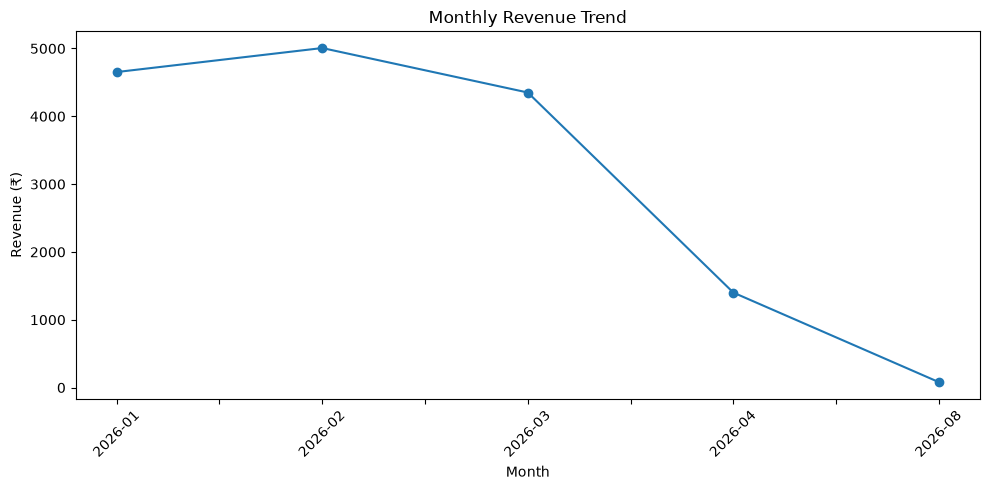

In [40]:
monthly_summary["TotalRevenue"].plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

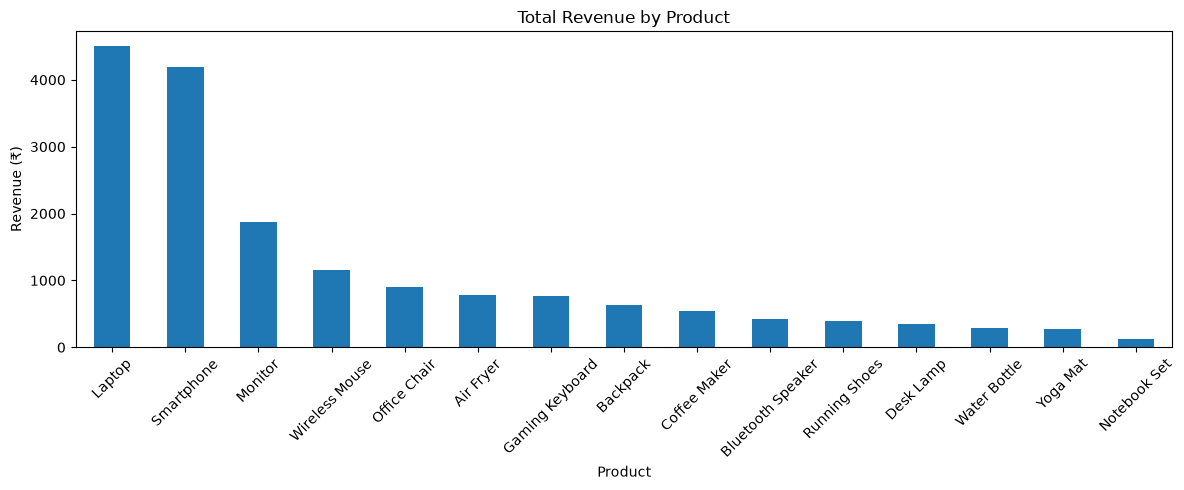

In [41]:
product_summary["TotalRevenue"].plot(kind="bar", figsize=(12, 5))
plt.title("Total Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [42]:
df['Region'].value_counts()

Region
Chennai       28
Bengaluru     13
Hyderabad      8
Mumbai         7
Pune           7
Delhi          7
Ahmedabad      6
Lucknow        6
Coimbatore     6
Kolkata        6
Jaipur         6
Name: count, dtype: Int64

In [43]:
df['Product'].unique()

<StringArray>
[           'Laptop',    'Wireless Mouse',      'Office Chair',
        'Smartphone',      'Coffee Maker',          'Backpack',
 'Bluetooth Speaker',      'Water Bottle',           'Monitor',
      'Notebook Set',   'Gaming Keyboard',          'Yoga Mat',
         'Air Fryer',     'Running Shoes',         'Desk Lamp',
                <NA>]
Length: 16, dtype: string

In [44]:
df['Revenue'].mean()

np.float64(186.4465053763441)

In [45]:
df['Revenue'].sum()

np.float64(17339.525)

In [46]:
df['Revenue'].min()

np.float64(24.950000000000003)

In [47]:
df['Revenue'].max()

np.float64(899.99)

In [48]:
df['Revenue'].median()

np.float64(89.97)

In [49]:
df['Revenue'].quantile([0.25, 0.5, 0.75])

0.25     49.00
0.50     89.97
0.75    149.50
Name: Revenue, dtype: float64

In [50]:
df.groupby(["Region", "Product"]).agg(
    TotalRevenue=("Revenue", "sum"),
    UnitsSold=("Units", "sum"),
    Orders=("OrderID", "nunique")
).reset_index().sort_values("TotalRevenue", ascending=False)

,Region,Product,TotalRevenue,UnitsSold,Orders
6,Chennai,Laptop,4499.950,10005.0,6
13,Hyderabad,Smartphone,4194.000,7.0,7
7,Chennai,Monitor,1179.940,6.0,6
9,Chennai,Wireless Mouse,899.990,1.0,1
17,Mumbai,Office Chair,897.000,6.0,6
3,Chennai,Air Fryer,779.940,6.0,6
1,Bengaluru,Gaming Keyboard,764.915,8.5,6
12,Hyderabad,Monitor,699.000,1.0,1
18,Pune,Coffee Maker,540.000,14.0,7
15,Kolkata,Backpack,539.820,18.0,6


In [51]:
df.groupby('Category')['Revenue'].agg(['count', 'sum', 'mean', 'min', 'max'])

,count,sum,mean,min,max
Category,,,,,
Electronics,37,12687.605,342.908243,29.99,899.99
Fashion,12,1029.740,85.811667,79.99,89.97
Furniture,7,1046.500,149.500000,149.50,149.50
Home & Kitchen,6,288.000,48.000000,48.00,48.00
Home Appliances,12,1319.940,109.995000,90.00,129.99
Home Decor,7,343.000,49.000000,49.00,49.00
Sports,6,270.000,45.000000,45.00,45.00
Stationery,5,124.750,24.950000,24.95,24.95


In [52]:
df[['OrderID', 'Revenue']].rename(columns={'Revenue': 'NetRevenue'}).head()

,OrderID,NetRevenue
0,ORD1001,899.99
1,ORD1002,39.98
2,ORD1003,149.50
3,ORD1004,699.00
4,ORD1005,90.00


In [53]:
df.drop(columns=['ReportedAmount']).head()

,OrderID,Date,CustomerID,Product,Category,Units,UnitPrice,PaymentMethod,OrderStatus,Region,Year,MonthNumber,Day,Month,DiscountPct,Revenue
0,ORD1001,2026-01-03,CUST001,Laptop,Electronics,1.0,899.99,Credit Card,Shipped,Chennai,2026.0,1.0,3.0,2026-01,0.0,899.99
1,ORD1002,2026-01-04,CUST002,Wireless Mouse,Electronics,2.0,19.99,Upi,Delivered,Bengaluru,2026.0,1.0,4.0,2026-01,0.0,39.98
2,ORD1003,2026-01-05,CUST003,Office Chair,Furniture,1.0,149.50,Cash On Delivery,Delivered,Mumbai,2026.0,1.0,5.0,2026-01,0.0,149.50
3,ORD1004,2026-01-06,CUST004,Smartphone,Electronics,1.0,699.00,<NA>,Processing,Hyderabad,2026.0,1.0,6.0,2026-01,0.0,699.00
4,ORD1005,2026-01-07,CUST005,Coffee Maker,Home Appliances,2.0,45.00,Upi,Delivered,Pune,2026.0,1.0,7.0,2026-01,0.0,90.00


In [54]:
df["RevenueBand"] = df["Revenue"].apply(
    lambda x: "Unknown" if pd.isna(x) else ("High" if x >= 500 else "Regular")
)
df[["OrderID", "Revenue", "RevenueBand"]].head()

,OrderID,Revenue,RevenueBand
0,ORD1001,899.99,High
1,ORD1002,39.98,Regular
2,ORD1003,149.50,Regular
3,ORD1004,699.00,High
4,ORD1005,90.00,Regular


In [55]:
df[['Units', 'UnitPrice', 'ReportedAmount', 'DiscountPct', 'Revenue']].corr(numeric_only=True)

,Units,UnitPrice,ReportedAmount,DiscountPct,Revenue
Units,1.000000,-0.009765,-0.010332,NaN,-0.369614
UnitPrice,-0.009765,1.000000,-0.010576,NaN,0.994053
ReportedAmount,-0.010332,-0.010576,1.000000,NaN,-0.057542
DiscountPct,NaN,NaN,NaN,NaN,NaN
Revenue,-0.369614,0.994053,-0.057542,NaN,1.000000


In [56]:
quality_summary = pd.Series({
    "Rows": len(df),
    "MissingDates": df["Date"].isna().sum(),
    "MissingProducts": df["Product"].isna().sum(),
    "MissingRegions": df["Region"].isna().sum(),
    "MissingUnits": df["Units"].isna().sum(),
    "InvalidUnits": ((df["Units"] <= 0) | (df["Units"] > 100)).sum(),
    "MissingUnitPrice": df["UnitPrice"].isna().sum(),
    "InvalidUnitPrice": ((df["UnitPrice"] <= 0) | (df["UnitPrice"] > 100000)).sum(),
    "MissingRevenue": df["Revenue"].isna().sum()
})
quality_summary

Rows                101
MissingDates          3
MissingProducts       1
MissingRegions        1
MissingUnits          2
InvalidUnits          2
MissingUnitPrice      2
InvalidUnitPrice      2
MissingRevenue        8
dtype: int64

In [57]:
region_summary.head(1)

,TotalRevenue,Orders,AverageRevenuePerOrder
Region,,,
Chennai,7876.75,28,291.731481


In [58]:
product_summary.head(1)

,TotalRevenue,UnitsSold,Orders
Product,,,
Laptop,4499.95,10005.0,6


In [59]:
monthly_summary.sort_values("TotalRevenue", ascending=False).head(1)

,TotalRevenue,Orders
Month,,
2026-02,5006.7,27


In [60]:
highest_revenue_orders

,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Revenue
0,ORD1001,2026-01-03,Chennai,Laptop,1.0,899.99,0.0,899.99
13,ORD1016,2026-01-18,Chennai,Laptop,1.0,899.99,0.0,899.99
28,ORD1031,2026-02-02,Chennai,Laptop,1.0,899.99,0.0,899.99
99,ORD1046,NaT,Chennai,Laptop,1.0,899.99,0.0,899.99
100,ORD1091,NaT,Chennai,Laptop,1.0,899.99,0.0,899.99
